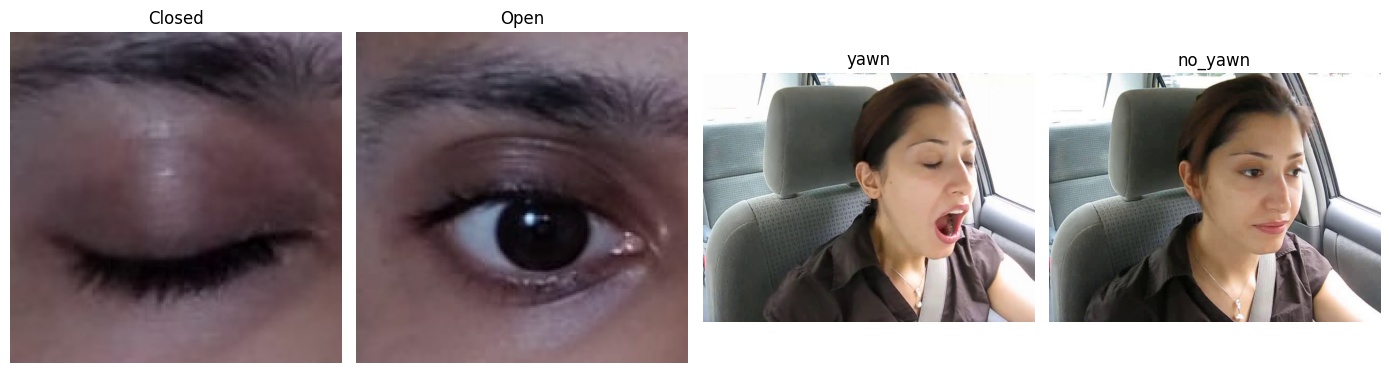

In [1]:
import os
import matplotlib.pyplot as plt
from PIL import Image

train_path = r"C:\Users\Nandani\Downloads\archive (13)\train"

categories = ["Closed", "Open", "yawn", "no_yawn"]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, category in zip(axes, categories):
    folder = os.path.join(train_path, category)
    image_file = next(
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    )

    image = Image.open(os.path.join(folder, image_file))
    ax.imshow(image)
    ax.set_title(category)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [2]:
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

X = []
y = []

labels = {"Closed": 0, "Open": 1, "yawn": 2, "no_yawn": 3}

for category, label in labels.items():
    folder = os.path.join(train_path, category)

    for file in os.listdir(folder):
        image_path = os.path.join(folder, file)

        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

        if image is None:
            continue

        image = cv2.resize(image, (64, 64))

        X.append(image.flatten())
        y.append(label)

X = np.array(X)
y = np.array(y)

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)
print("Classes:", labels)

Dataset shape: (2900, 4096)
Labels shape: (2900,)
Classes: {'Closed': 0, 'Open': 1, 'yawn': 2, 'no_yawn': 3}


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=labels.keys()))

Accuracy: 0.9586206896551724

Classification Report:

              precision    recall  f1-score   support

      Closed       0.96      0.93      0.94       145
        Open       0.94      0.95      0.95       145
        yawn       0.98      0.97      0.97       145
     no_yawn       0.96      0.99      0.97       145

    accuracy                           0.96       580
   macro avg       0.96      0.96      0.96       580
weighted avg       0.96      0.96      0.96       580



In [4]:
import cv2
import mediapipe as mp

print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("MediaPipe solutions available:", hasattr(mp, "solutions"))

OpenCV: 5.0.0
MediaPipe: 1.2.0
MediaPipe solutions available: False


In [5]:
import cv2
import mediapipe as mp

print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("Old Face Mesh API available:", hasattr(mp, "solutions"))

OpenCV: 5.0.0
MediaPipe: 1.2.0
Old Face Mesh API available: False


In [6]:
import cv2
import mediapipe as mp
import os

print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)

print("Tasks API available:", hasattr(mp, "tasks"))
print("Current folder:", os.getcwd())

OpenCV: 5.0.0
MediaPipe: 1.2.0
Tasks API available: True
Current folder: C:\Users\Nandani\DriverDrowsiness


In [7]:
import os
import urllib.request

model_path = os.path.abspath("face_landmarker.task")

model_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/1/"
    "face_landmarker.task"
)

if not os.path.exists(model_path):
    urllib.request.urlretrieve(model_url, model_path)

print("Model downloaded:", os.path.exists(model_path))
print("Model location:", model_path)

Model downloaded: True
Model location: C:\Users\Nandani\DriverDrowsiness\face_landmarker.task


In [8]:
import cv2

cap = cv2.VideoCapture(0)

print("Webcam opened:", cap.isOpened())

cap.release()

Webcam opened: True


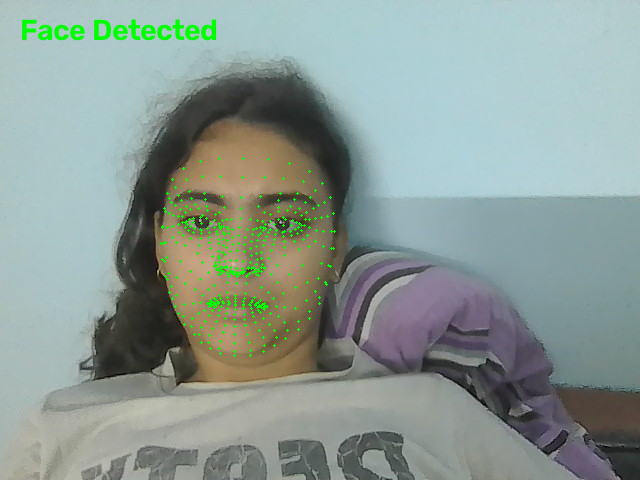

Webcam stopped.


KeyboardInterrupt: 

In [9]:
import cv2
import mediapipe as mp
import time
from IPython.display import display, clear_output
from PIL import Image

BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=model_path),
    running_mode=RunningMode.VIDEO,
    num_faces=1
)

landmarker = FaceLandmarker.create_from_options(options)

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Webcam open nahi hua!")
else:
    print("Webcam started! Stop karne ke liye cell ka Stop button dabao.")

    try:
        for _ in range(300):
            ret, frame = cap.read()

            if not ret:
                print("Frame read nahi ho raha.")
                break

            frame = cv2.flip(frame, 1)
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )

            timestamp = int(time.time() * 1000)
            result = landmarker.detect_for_video(mp_image, timestamp)

            if result.face_landmarks:
                h, w, _ = frame.shape

                for point in result.face_landmarks[0]:
                    x, y = int(point.x * w), int(point.y * h)
                    cv2.circle(frame, (x, y), 1, (0, 255, 0), -1)

                cv2.putText(
                    frame, "Face Detected", (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2
                )

            clear_output(wait=True)
            display(Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)))

            time.sleep(0.03)

    finally:
        cap.release()
        landmarker.close()
        print("Webcam stopped.")

In [10]:
import cv2
import mediapipe as mp
import numpy as np
import time
import winsound

from IPython.display import display, clear_output, Image
from PIL import Image as PILImage


# -------------------------------
# 1. SETTINGS
# -------------------------------

model_path = "face_landmarker.task"

EAR_THRESHOLD = 0.21
CLOSED_SECONDS = 2.0

LEFT_EYE = [362, 385, 387, 263, 373, 380]
RIGHT_EYE = [33, 160, 158, 133, 153, 144]


# -------------------------------
# 2. EAR CALCULATION
# -------------------------------

def calculate_ear(landmarks, eye_indices, width, height):

    points = []

    for index in eye_indices:
        x = int(landmarks[index].x * width)
        y = int(landmarks[index].y * height)
        points.append(np.array([x, y]))

    vertical_1 = np.linalg.norm(points[1] - points[5])
    vertical_2 = np.linalg.norm(points[2] - points[4])
    horizontal = np.linalg.norm(points[0] - points[3])

    if horizontal == 0:
        return 0.0

    ear = (vertical_1 + vertical_2) / (2.0 * horizontal)

    return ear


# -------------------------------
# 3. MEDIAPIPE FACE LANDMARKER
# -------------------------------

BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=model_path),
    running_mode=RunningMode.VIDEO,
    num_faces=1
)


# -------------------------------
# 4. START WEBCAM
# -------------------------------

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Webcam open nahi hua. Camera check karo.")

else:
    closed_start = None
    alarm_playing = False
    last_timestamp = 0

    try:
        with FaceLandmarker.create_from_options(options) as landmarker:

            while True:

                success, frame = cap.read()

                if not success:
                    print("Camera se frame nahi mil raha.")
                    break

                # Mirror effect
                frame = cv2.flip(frame, 1)

                height, width = frame.shape[:2]

                # BGR to RGB
                rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

                mp_image = mp.Image(
                    image_format=mp.ImageFormat.SRGB,
                    data=rgb_frame
                )

                # MediaPipe requires increasing timestamps
                timestamp = max(
                    int(time.time() * 1000),
                    last_timestamp + 1
                )
                last_timestamp = timestamp

                result = landmarker.detect_for_video(
                    mp_image,
                    timestamp
                )

                status = "No face detected"
                color = (255, 255, 0)

                if result.face_landmarks:

                    landmarks = result.face_landmarks[0]

                    left_ear = calculate_ear(
                        landmarks, LEFT_EYE, width, height
                    )

                    right_ear = calculate_ear(
                        landmarks, RIGHT_EYE, width, height
                    )

                    ear = (left_ear + right_ear) / 2.0

                    # Draw eye landmark points
                    for index in LEFT_EYE + RIGHT_EYE:
                        x = int(landmarks[index].x * width)
                        y = int(landmarks[index].y * height)

                        cv2.circle(
                            frame,
                            (x, y),
                            2,
                            (0, 255, 255),
                            -1
                        )

                    # -------------------------------
                    # 5. DROWSINESS DETECTION
                    # -------------------------------

                    if ear < EAR_THRESHOLD:

                        if closed_start is None:
                            closed_start = time.time()

                        closed_duration = time.time() - closed_start

                        if closed_duration >= CLOSED_SECONDS:

                            status = "DROWSINESS ALERT!"
                            color = (0, 0, 255)

                            # Play alarm only once until eyes reopen
                            if not alarm_playing:
                                alarm_playing = True
                                winsound.Beep(1000, 500)

                        else:
                            status = "Eyes closing..."
                            color = (0, 165, 255)

                    else:
                        closed_start = None
                        alarm_playing = False

                        status = "Awake"
                        color = (0, 255, 0)

                    # Display EAR value
                    cv2.putText(
                        frame,
                        f"EAR: {ear:.2f}",
                        (20, 40),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.8,
                        (255, 255, 255),
                        2
                    )

                else:
                    closed_start = None
                    alarm_playing = False

                # Display status
                cv2.putText(
                    frame,
                    status,
                    (20, 85),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.8,
                    color,
                    2
                )

                # Show webcam in Jupyter
                display(
                    Image(
                        data=cv2.imencode(".jpg", frame)[1].tobytes()
                    )
                )

                clear_output(wait=True)
                time.sleep(0.03)

    except KeyboardInterrupt:
        print("Drowsiness detection stopped.")

    except Exception as error:
        print("Error:", error)

    finally:
        cap.release()
        cv2.destroyAllWindows()
        print("Webcam released.")

Drowsiness detection stopped.
Webcam released.


In [14]:
import os

models_path = r"C:\Users\Nandani\DriverDrowsiness\models"

for file in os.listdir(models_path):
    print(file)

.ipynb_checkpoints
Untitled.ipynb


In [15]:
import os
import joblib

models_folder = r"C:\Users\Nandani\DriverDrowsiness\models"
os.makedirs(models_folder, exist_ok=True)

save_path = os.path.join(models_folder, "drowsiness_rf.joblib")

joblib.dump(model, save_path)

print("✅ Model saved successfully!")
print("File location:", save_path)

✅ Model saved successfully!
File location: C:\Users\Nandani\DriverDrowsiness\models\drowsiness_rf.joblib


In [16]:
import joblib

model_path = r"C:\Users\Nandani\DriverDrowsiness\models\drowsiness_rf.joblib"

loaded_model = joblib.load(model_path)

print("✅ Model loaded successfully!")
print("Model type:", type(loaded_model))
print("Expected features:", loaded_model.n_features_in_)

✅ Model loaded successfully!
Model type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Expected features: 4096


In [17]:


print(labels)
print(X_train.shape)
print(X_test.shape)

{'Closed': 0, 'Open': 1, 'yawn': 2, 'no_yawn': 3}
(2320, 4096)
(580, 4096)
